# Macao visitor mix and hotel occupancy, 2023–2025

Guanyu Ke · Ongoing course project

**Question:** Which visitor type supplied the increase in visitor arrivals, and how did hotel occupancy change over the same 36 months?

**Data:** Original DSEC monthly aggregate series exported from MGTO Tourism Statistics, Total markets and Total hotel establishments. Raw files are preserved locally. See README for download and checksum instructions; they are not redistributed in this public repository.

**Methods:** Validate one-to-one month matching, sum annual arrivals, calculate same-day share and growth contributions, and compare monthly series in separate panels. Annual occupancy below is an unweighted mean of monthly rates, not an official annual occupancy rate.

In [1]:
%matplotlib inline
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

BASE = Path(__file__).resolve().parent if '__file__' in globals() else Path.cwd()
RAW = BASE / 'data' / 'raw'
FIG = BASE / 'figures'
FIG.mkdir(exist_ok=True)

# Inspect raw headers, then select explicitly named measures.
visitors_raw = pd.read_csv(RAW / 'visitors.csv', encoding='utf-8-sig')
hotels_raw = pd.read_csv(RAW / 'hotel.csv', encoding='utf-8-sig')
print('Raw shapes:', visitors_raw.shape, hotels_raw.shape)
print('Visitor columns:', visitors_raw.columns.tolist())
print('Hotel columns:', hotels_raw.columns.tolist())
visitors = visitors_raw[['Year','Month','Source Markets','SameDay','OverNight']].copy()
hotels = hotels_raw[['Year','Month','Hotel Establishments','Occupancy rate']].copy()
visitors = visitors[visitors['Source Markets'] == 'Total']
hotels = hotels[hotels['Hotel Establishments'] == 'Total']
visitors = visitors.rename(columns={'Year':'year','Month':'month','SameDay':'same_day','OverNight':'overnight'})
hotels = hotels.rename(columns={'Year':'year','Month':'month','Occupancy rate':'occupancy_pct'})
assert not visitors.duplicated(['year','month']).any()
assert not hotels.duplicated(['year','month']).any()
monthly = visitors[['year','month','same_day','overnight']].merge(
    hotels[['year','month','occupancy_pct']], on=['year','month'], how='outer', validate='one_to_one', indicator=True)
assert monthly['_merge'].eq('both').all()
monthly = monthly.drop(columns='_merge').sort_values(['year','month']).reset_index(drop=True)
assert len(monthly) == 36 and not monthly.isna().any().any()
assert monthly['occupancy_pct'].between(0,100).all()
assert monthly[['same_day','overnight']].ge(0).all().all()
monthly['date'] = pd.to_datetime(dict(year=monthly.year,month=monthly.month,day=1))
assert monthly.date.tolist() == pd.date_range('2023-01-01','2025-12-01',freq='MS').tolist()
monthly['total'] = monthly.same_day + monthly.overnight
monthly['same_day_share_pct'] = monthly.same_day / monthly.total * 100
annual = monthly.groupby('year').agg(same_day=('same_day','sum'),overnight=('overnight','sum'),mean_monthly_occupancy_pct=('occupancy_pct','mean'))
annual['total'] = annual.same_day + annual.overnight
annual['same_day_share_pct'] = annual.same_day / annual.total * 100
increase = annual[['same_day','overnight','total']].diff().dropna()
increase['same_day_contribution_pct'] = increase.same_day / increase.total * 100
assert annual.loc[2025,'total'] == 40069360
assert annual.loc[2025,'same_day'] == 23524943
assert annual.loc[2025,'overnight'] == 16544417
print(annual.round(2).to_string())
print(increase.round(2).to_string())


Raw shapes: (36, 12) (36, 8)
Visitor columns: ['Year', 'Quarter', 'Month', 'Source Markets', 'SameDay', 'Remark', 'SameDay Year of Year Changes', 'Remark.1', 'OverNight', 'Remark.2', 'OverNight Year of Year Changes', 'Remark.3']
Hotel columns: ['Year', 'Quarter', 'Month', 'Hotel Establishments', 'Occupancy rate', 'Remark', 'Difference', 'Remark.1']
      same_day  overnight  mean_monthly_occupancy_pct     total  same_day_share_pct
year                                                                               
2023  13985774   14227229                       81.21  28213003               49.57
2024  18884882   16043768                       86.35  34928650               54.07
2025  23524943   16544417                       89.43  40069360               58.71
       same_day  overnight      total  same_day_contribution_pct
year                                                            
2024  4899108.0  1816539.0  6715647.0                      72.95
2025  4640061.0   500649.0  514071

## Monthly comparison

Lines show change over time. Separate aligned panels preserve the different units. Both vertical axes start at zero.

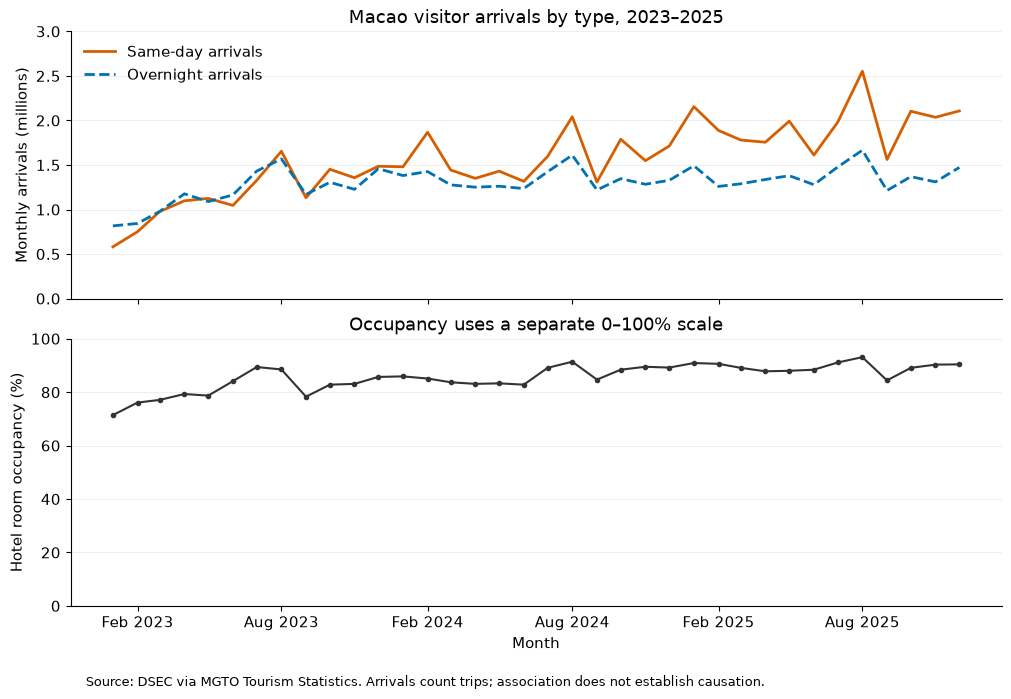

In [2]:
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':11,'axes.spines.top':False,'axes.spines.right':False})
fig,(ax1,ax2)=plt.subplots(2,1,figsize=(10,7),sharex=True,layout='constrained')
ax1.plot(monthly.date,monthly.same_day/1e6,label='Same-day arrivals',color='#D55E00',lw=2)
ax1.plot(monthly.date,monthly.overnight/1e6,label='Overnight arrivals',color='#0072B2',lw=2,linestyle='--')
ax1.set(ylabel='Monthly arrivals (millions)',ylim=(0,3),title='Macao visitor arrivals by type, 2023–2025')
ax1.legend(loc='upper left',frameon=False)
ax2.plot(monthly.date,monthly.occupancy_pct,color='#333333',marker='o',ms=3)
ax2.set(ylabel='Hotel room occupancy (%)',ylim=(0,100),xlabel='Month',title='Occupancy uses a separate 0–100% scale')
ax2.xaxis.set_major_locator(mdates.MonthLocator(interval=6));ax2.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
for ax in [ax1,ax2]:ax.grid(axis='y',alpha=.2)
fig.get_layout_engine().set(rect=(0,.055,1,.93))
fig.text(.08,.012,'Source: DSEC via MGTO Tourism Statistics. Arrivals count trips; association does not establish causation.',fontsize=9)
fig.savefig(FIG/'monthly_arrivals_occupancy.png',dpi=180);plt.show()


## Contributions to annual growth

Stacked lengths add to the total increase; values are calculated from annual sums.

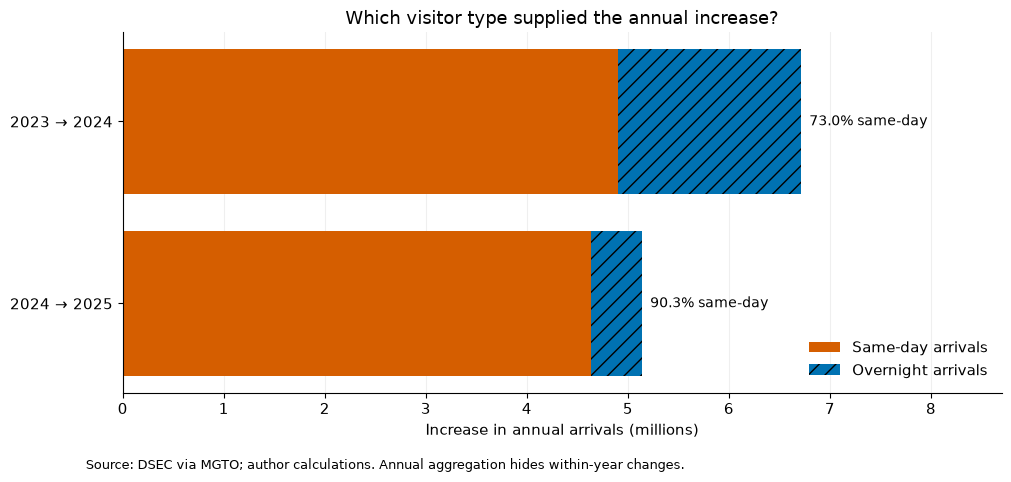

In [3]:
fig,ax=plt.subplots(figsize=(10,4.8),layout='constrained')
labels=['2023 → 2024','2024 → 2025']
ax.barh(labels,increase.same_day/1e6,label='Same-day arrivals',color='#D55E00')
ax.barh(labels,increase.overnight/1e6,left=increase.same_day/1e6,label='Overnight arrivals',color='#0072B2',hatch='//')
for y,(_,r) in enumerate(increase.iterrows()):
 ax.text(r.total/1e6+.08,y,f'{r.same_day_contribution_pct:.1f}% same-day',va='center',fontsize=10)
ax.set(xlabel='Increase in annual arrivals (millions)',xlim=(0,8.7),title='Which visitor type supplied the annual increase?')
ax.invert_yaxis();ax.legend(loc='lower right',frameon=False);ax.grid(axis='x',alpha=.2);ax.set_axisbelow(True)
fig.get_layout_engine().set(rect=(0,.07,1,.91));fig.text(.08,.015,'Source: DSEC via MGTO; author calculations. Annual aggregation hides within-year changes.',fontsize=9)
fig.savefig(FIG/'annual_growth_contributions.png',dpi=180);plt.show()


## Interpretation and limitations

Same-day arrivals supplied about 90% of the increase from 2024 to 2025. Their share of all arrivals rose from about 50% in 2023 to 59% in 2025. Mean monthly occupancy rose from about 81% to 89% across the same years.

This does not demonstrate that hotel capacity caused more same-day visits. Arrivals are trips rather than unique people; overnight visitors need not stay in hotels. Room supply, room prices, source-market composition and earlier baseline years are absent. Future work should add these variables and compare seasonal patterns before attempting explanatory claims.